# 03 · Model: which orders will arrive late?

Goal: at purchase time, rank orders by their risk of not arriving on time, so that action can be taken on the riskiest ones (adjust the promised date or prioritize the shipment).

Protocol:

| Step | Detail |
|---|---|
| Candidates | A simple rule, logistic regression and gradient boosting |
| Selection | Chosen on a validation period: purchases from January to March 2018 |
| Test | Reported once on the test period: purchases from April to August 2018, with bootstrap confidence intervals |
| Stability | A month-by-month backtest checks that the result does not depend on a single cutoff |
| Training data | At each cutoff, only orders whose outcome was already known before the evaluated period started |

Main metric: % of late orders caught when reviewing the riskiest 10% of orders. It answers the business question directly: if the logistics team can only handle 1 in 10 orders, how many delays can it prevent? AUC-PR (suited to imbalanced classes) and AUC-ROC are reported as supporting metrics.

In [1]:
import json
import sys
import warnings
from dataclasses import asdict, dataclass

sys.path.insert(0, "../src")
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from features import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET, build_features, load_model_base
from plot_style import AQUA, BLUE, GRAY, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"


@dataclass
class Config:
    seed: int = 42
    val_start: str = "2018-01-01"
    test_start: str = "2018-04-01"
    test_end: str = "2018-09-01"
    capacity: float = 0.10          # share of orders the team can handle
    n_bootstrap: int = 1000
    backtest_first_month: str = "2017-10-01"


cfg = Config()
np.random.seed(cfg.seed)
df = load_model_base("../data/processed/model_base.csv")

## 1. Candidates

- Simple rule: sort by `promise_ratio` from lowest to highest. Orders with the shortest buffer (promised days ÷ the route's historical days) are the riskiest. It is not trained; it only uses history.
- Logistic regression: 26 features; scaling and imputation inside a `Pipeline` and one-hot encoding of the categorical features.
- Gradient boosting (scikit-learn's `HistGradientBoostingClassifier`, the same histogram-based tree technique as XGBoost and LightGBM): native handling of categorical features and moderate regularization.

In [2]:
def make_logistic() -> Pipeline:
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL_FEATURES),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=3000, C=0.5))


def to_boosting_frame(train: pd.DataFrame, other: pd.DataFrame):
    """Convert categorical features to 'category' using ONLY the categories seen in training."""
    a, b = train[FEATURES].copy(), other[FEATURES].copy()
    for col in CATEGORICAL_FEATURES:
        cats = pd.Index(a[col].dropna().unique())
        a[col] = pd.Categorical(a[col], categories=cats)
        b[col] = pd.Categorical(b[col].where(b[col].isin(cats)), categories=cats)
    return a, b


def make_boosting(seed: int) -> HistGradientBoostingClassifier:
    return HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200,
        l2_regularization=1.0, categorical_features="from_dtype",
        early_stopping=False, random_state=seed,
    )


def split_at(start: pd.Timestamp, end: pd.Timestamp):
    """
    Build features with priors computed before `start` and split into:
    - train: orders whose OUTCOME was known before `start`
    - evaluation: orders PLACED in [start, end)
    Leakage audit: no training order has an outcome after the start of the
    evaluated period, and no evaluated order is in training (all of them
    were placed on or after `start`).
    """
    X = build_features(df, cutoff=start)
    train = X[X.outcome_known_ts < start]
    evaluation = X[(X.purchase_ts >= start) & (X.purchase_ts < end)]
    assert train.order_id.isin(evaluation.order_id).sum() == 0
    return train, evaluation


def score_all(train: pd.DataFrame, evaluation: pd.DataFrame, seed: int = 42):
    """Return risk scores (higher = riskier) for the three candidates."""
    logistic = make_logistic().fit(train[FEATURES], train[TARGET])
    a, b = to_boosting_frame(train, evaluation)
    boosting = make_boosting(seed).fit(a, train[TARGET])
    scores = {
        "Rule: promise buffer": -evaluation["promise_ratio"].to_numpy(),
        "Logistic regression": logistic.predict_proba(evaluation[FEATURES])[:, 1],
        "Gradient boosting": boosting.predict_proba(b)[:, 1],
    }
    return scores, {"logistic": logistic, "boosting": boosting}


def capture_at(y: np.ndarray, score: np.ndarray, k: float) -> float:
    """Share of positives that fall in the top k% of orders by score."""
    n = int(round(len(score) * k))
    top = np.argsort(-score, kind="stable")[:n]
    return y[top].sum() / y.sum()


def metrics(y: np.ndarray, score: np.ndarray, k: float) -> dict:
    return {
        "capture_top10": capture_at(y, score, k),
        "precision_top10": y[np.argsort(-score, kind="stable")[: int(round(len(score) * k))]].mean(),
        "auc_pr": average_precision_score(y, score),
        "auc_roc": roc_auc_score(y, score),
    }

## 2. A prior decision: all-time or recent route history?

`promise_ratio` divides the promised days by how long the route has historically taken. In 2018 deliveries sped up a lot, so an all-time average going back to 2017 makes routes look slow when they no longer are.

I compare several windows on the validation period only, using the rule as is. The chosen window (90 days) is the one `src/features.py` uses.

In [3]:
import features as feat

val_start, val_end = pd.Timestamp(cfg.val_start), pd.Timestamp(cfg.test_start)
Xv = build_features(df, cutoff=val_start)
in_val = (Xv.purchase_ts >= val_start) & (Xv.purchase_ts < val_end)
global_days = Xv.loc[Xv.delivered_ts < val_start, "actual_days"].mean()
window_rows = []
for label, days in [("All-time (full history)", 10_000), ("Last 180 days", 180),
                    ("Last 90 days", 90), ("Last 60 days", 60)]:
    route_days = feat._history_mean_days(Xv, "route", global_days, window_days=days)
    ratio = (Xv.promised_days / route_days)[in_val].to_numpy()
    y = Xv.loc[in_val, TARGET].to_numpy()
    window_rows.append({"route history": label, "capture_top10": capture_at(y, -ratio, cfg.capacity),
                        "auc_pr": average_precision_score(y, -ratio)})
pd.DataFrame(window_rows).set_index("route history").round(3)

,capture_top10,auc_pr
route history,,
All-time (full history),0.226,0.260
Last 180 days,0.265,0.290
Last 90 days,0.269,0.310
Last 60 days,0.258,0.301


## 3. Selection on the validation period (January to March 2018)

In [4]:
val_train, val = split_at(pd.Timestamp(cfg.val_start), pd.Timestamp(cfg.test_start))
print(f"Training: {len(val_train):,} orders · Validation: {len(val):,} orders "
      f"({val[TARGET].mean():.1%} late)")
val_scores, _ = score_all(val_train, val, cfg.seed)
y_val = val[TARGET].to_numpy()
val_table = pd.DataFrame({name: metrics(y_val, s, cfg.capacity) for name, s in val_scores.items()}).T
val_table.round(3)

Training: 41,748 orders · Validation: 20,891 orders (14.0% late)


,capture_top10,precision_top10,auc_pr,auc_roc
Rule: promise buffer,0.269,0.376,0.310,0.708
Logistic regression,0.254,0.356,0.283,0.700
Gradient boosting,0.194,0.272,0.218,0.648


On validation the rule wins on every metric:
- it catches 26.9% of late orders, against 25.4% for logistic regression and 19.4% for gradient boosting;
- it also needs no training, can be explained in one sentence and does not depend on 25 more features.

Following the protocol, the rule is the selected option. Even so, all three candidates go on to the test set to confirm the decision with data none of them has seen.

## 4. Results on the test period (April to August 2018)

In [5]:
train, test = split_at(pd.Timestamp(cfg.test_start), pd.Timestamp(cfg.test_end))
print(f"Training: {len(train):,} orders (outcome known before {cfg.test_start}) · "
      f"Test: {len(test):,} orders ({test[TARGET].mean():.1%} late)")
test_scores, models = score_all(train, test, cfg.seed)
y_test = test[TARGET].to_numpy()

rng = np.random.default_rng(cfg.seed)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(cfg.n_bootstrap)]
rule_name = "Rule: promise buffer"

rows = []
for name, s in test_scores.items():
    point = metrics(y_test, s, cfg.capacity)
    boot = pd.DataFrame([metrics(y_test[i], s[i], cfg.capacity) for i in boot_idx])
    diff = [capture_at(y_test[i], s[i], cfg.capacity) - capture_at(y_test[i], test_scores[rule_name][i], cfg.capacity)
            for i in boot_idx]
    rows.append({
        "model": name,
        "capture_top10": f"{point['capture_top10']:.1%} ({boot.capture_top10.quantile(.025):.1%}–{boot.capture_top10.quantile(.975):.1%})",
        "precision_top10": f"{point['precision_top10']:.1%}",
        "auc_pr": f"{point['auc_pr']:.3f} ({boot.auc_pr.quantile(.025):.3f}–{boot.auc_pr.quantile(.975):.3f})",
        "auc_roc": f"{point['auc_roc']:.3f} ({boot.auc_roc.quantile(.025):.3f}–{boot.auc_roc.quantile(.975):.3f})",
        "capture_diff_vs_rule": "—" if name == rule_name else
            f"{np.mean(diff):+.1%} ({np.quantile(diff, .025):+.1%} to {np.quantile(diff, .975):+.1%})",
    })
test_table = pd.DataFrame(rows).set_index("model")
print(f"Base rate: {y_test.mean():.1%} · 95% bootstrap intervals ({cfg.n_bootstrap} resamples)")
test_table

Training: 61,532 orders (outcome known before 2018-04-01) · Test: 32,453 orders (5.3% late)
Base rate: 5.3% · 95% bootstrap intervals (1000 resamples)


,capture_top10,precision_top10,auc_pr,auc_roc,capture_diff_vs_rule
model,,,,,
Rule: promise buffer,29.4% (27.4%–31.3%),15.6%,0.133 (0.123–0.146),0.718 (0.705–0.730),—
Logistic regression,26.0% (24.2%–28.0%),13.8%,0.115 (0.107–0.127),0.685 (0.673–0.698),-3.4% (-5.8% to -0.8%)
Gradient boosting,25.9% (24.1%–27.9%),13.8%,0.120 (0.110–0.132),0.697 (0.684–0.709),-3.5% (-5.8% to -1.0%)


- Rule capture: reviewing the 10% of orders with the shortest buffer catches 29.4% of all late orders (95% CI: 27.4%–31.3%), almost 3 times more than reviewing at random (10%).
- Comparison with the models: both fall below the rule, by about 3.5 points of capture. Their difference intervals exclude zero, so the gap is not noise.
- Conclusion: adding 25 more features does not buy out-of-sample accuracy; with the 2018 regime change, what the models learned from the past ages faster than a rule based on the route's recent history.
- AUC-PR and base rate: the test AUC-PR (~0.12–0.13) is lower than on validation (~0.22–0.31) because the base late rate fell from 14% to 5%; it does not mean performance got worse.

## 5. Capture curve

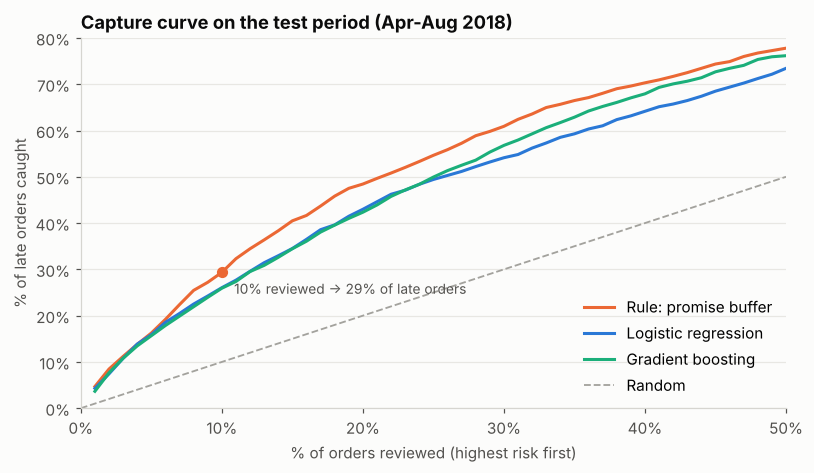

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ks = np.linspace(0.01, 0.5, 50)
palette = {rule_name: ORANGE, "Logistic regression": BLUE, "Gradient boosting": AQUA}
for name, s in test_scores.items():
    ax.plot(100 * ks, [100 * capture_at(y_test, s, k) for k in ks], color=palette[name], label=name)
ax.plot([0, 50], [0, 50], color=GRAY, linestyle="--", linewidth=1.2, label="Random")
cap_rule = capture_at(y_test, test_scores[rule_name], cfg.capacity)
ax.scatter([10], [100 * cap_rule], color=ORANGE, s=40, zorder=3)
ax.annotate(f"10% reviewed → {cap_rule:.0%} of late orders", (10, 100 * cap_rule),
            textcoords="offset points", xytext=(8, -14), fontsize=9, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("% of orders reviewed (highest risk first)")
ax.set_ylabel("% of late orders caught")
ax.set_title("Capture curve on the test period (Apr-Aug 2018)")
ax.legend(loc="lower right")
ax.set_xlim(0, 50)
ax.set_ylim(0, 80)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_capture_curve_test.png", dpi=160)

## 6. Month-by-month backtest

A single cutoff can be misleading. For each month from October 2017 to August 2018, the whole procedure is repeated:
1. features are built with priors from before that month;
2. the models are trained on everything known before the month;
3. they are evaluated on that month's purchases.

In [7]:
backtest = []
for month in pd.date_range(cfg.backtest_first_month, "2018-08-01", freq="MS"):
    tr, ev = split_at(month, month + pd.offsets.MonthBegin(1))
    scores, _ = score_all(tr, ev, cfg.seed)
    y = ev[TARGET].to_numpy()
    for name, s in scores.items():
        backtest.append({"month": month.strftime("%Y-%m"), "model": name, "orders": len(ev),
                         "late_rate": y.mean(), "capture_top10": capture_at(y, s, cfg.capacity),
                         "auc_pr": average_precision_score(y, s)})
backtest = pd.DataFrame(backtest)
capture_by_month = backtest.pivot(index="month", columns="model", values="capture_top10")
capture_by_month[[rule_name, "Logistic regression", "Gradient boosting"]].round(3)

model,Rule: promise buffer,Logistic regression,Gradient boosting
month,,,
2017-10,0.214,0.191,0.164
2017-11,0.167,0.197,0.200
2017-12,0.203,0.179,0.141
2018-01,0.256,0.214,0.197
2018-02,0.310,0.270,0.166
2018-03,0.196,0.244,0.192
2018-04,0.279,0.326,0.262
2018-05,0.229,0.268,0.308
2018-06,0.333,0.289,0.333


In [8]:
summary = pd.DataFrame({
    "mean_capture_top10": capture_by_month.mean(),
    "std_dev": capture_by_month.std(),
    "months_beating_the_rule": (capture_by_month.gt(capture_by_month[rule_name], axis=0)).sum(),
}).loc[[rule_name, "Logistic regression", "Gradient boosting"]]
summary["months_beating_the_rule"] = summary["months_beating_the_rule"].astype(int)
summary.loc[rule_name, "months_beating_the_rule"] = None
print(f"Months evaluated: {capture_by_month.shape[0]}")
summary.round(3)

Months evaluated: 11


,mean_capture_top10,std_dev,months_beating_the_rule
model,,,
Rule: promise buffer,0.247,0.051,NaN
Logistic regression,0.235,0.051,4.0
Gradient boosting,0.209,0.071,2.0


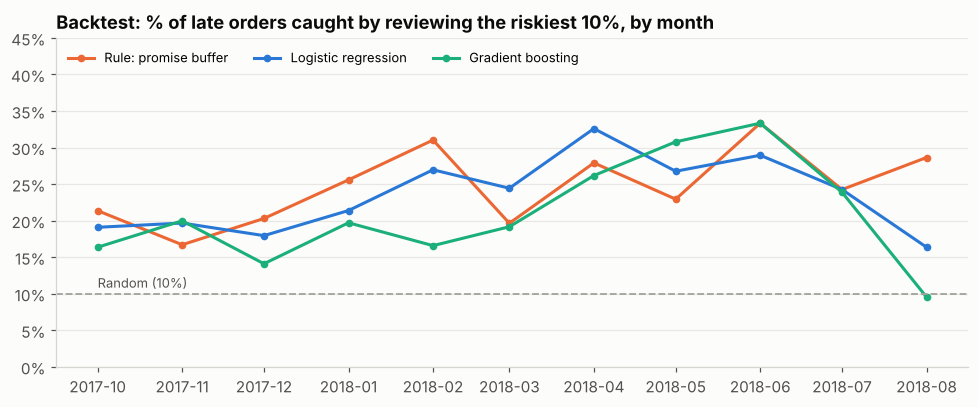

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
months = pd.to_datetime(capture_by_month.index)
for name in [rule_name, "Logistic regression", "Gradient boosting"]:
    ax.plot(months, 100 * capture_by_month[name], color=palette[name], marker="o", markersize=4, label=name)
ax.axhline(10, color=GRAY, linestyle="--", linewidth=1.2)
ax.annotate("Random (10%)", (months[0], 10), textcoords="offset points", xytext=(0, 4), fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 45)
ax.set_title("Backtest: % of late orders caught by reviewing the riskiest 10%, by month")
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_backtest_monthly_capture.png", dpi=160)

The backtest confirms what the test showed:

- The rule has the best average: 24.7% capture, against 23.5% for logistic regression and 20.9% for gradient boosting. The models beat it in only 4 and 2 of 11 months, respectively.
- The rule is the most stable in the worst case: it never drops below 16.7%.
- Gradient boosting ages badly: in August 2018, when promised times were cut sharply, it catches 9.5%, below random. That is the typical sign of a model that learned patterns from a period that no longer exists.

## 7. What did the model learn? Permutation importance

For gradient boosting, on the test period: how much AUC-PR drops when the values of each feature are shuffled at random. I use this method because it measures importance on data the model did not see.

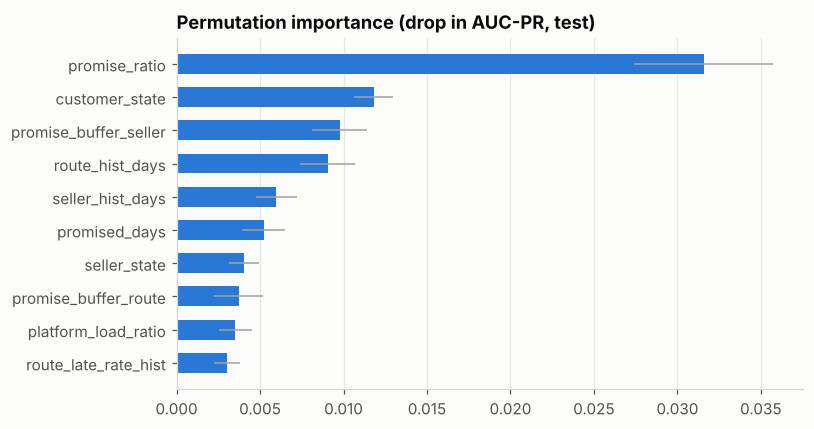

,feature,auc_pr_drop,std
0,promise_ratio,0.0316,0.0042
1,customer_state,0.0118,0.0012
2,promise_buffer_seller,0.0098,0.0017
3,route_hist_days,0.0090,0.0016
4,seller_hist_days,0.0060,0.0013
5,promised_days,0.0052,0.0013
6,seller_state,0.0040,0.0009
7,promise_buffer_route,0.0037,0.0015
8,platform_load_ratio,0.0035,0.0010
9,route_late_rate_hist,0.0030,0.0008


In [10]:
_, test_boost = to_boosting_frame(train, test)
perm = permutation_importance(models["boosting"], test_boost, y_test, scoring="average_precision",
                              n_repeats=5, random_state=cfg.seed, n_jobs=-1)
importance = (pd.DataFrame({"feature": FEATURES, "auc_pr_drop": perm.importances_mean, "std": perm.importances_std})
              .sort_values("auc_pr_drop", ascending=False).reset_index(drop=True))

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top.feature, top.auc_pr_drop, xerr=top["std"], color=BLUE, height=0.6,
        error_kw={"ecolor": GRAY, "elinewidth": 1})
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance (drop in AUC-PR, test)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/06_permutation_importance.png", dpi=160)
importance.head(10).round(4)

The complex model relies, by far, on the same signal the rule uses: `promise_ratio`. Its importance is almost three times that of the next feature. It is followed by customer state, the seller-level buffer and how long the route takes.

The model does not find extra information that makes up for the risk of memorizing the past; that is why it cannot beat the rule.

## 8. Operating policy: a threshold that updates itself

To operate day to day you cannot "take the riskiest 10% of the month" before the month is over. You need a threshold that is known at the moment of purchase.

First attempt: a fixed threshold calibrated on validation (the `promise_ratio` value that flagged 10% of orders).

Alternative: a rolling threshold. Each day, the threshold is the 10th percentile of `promise_ratio` over the orders from the previous 30 days. It updates itself, with no retraining.

In [11]:
fixed_threshold = float(np.quantile(val["promise_ratio"], cfg.capacity))
fixed_flag = test["promise_ratio"].to_numpy() < fixed_threshold

# Rolling threshold: 10th percentile of the previous 30 days (information available at purchase time)
all_orders = build_features(df, cutoff=pd.Timestamp(cfg.test_start))[["purchase_ts", "promise_ratio"]]
daily_threshold = {}
for day in pd.date_range(cfg.test_start, pd.Timestamp(cfg.test_end) - pd.Timedelta(days=1), freq="D"):
    window = all_orders[(all_orders.purchase_ts >= day - pd.Timedelta(days=30)) & (all_orders.purchase_ts < day)]
    daily_threshold[day] = window.promise_ratio.quantile(cfg.capacity)
test_threshold = test.purchase_ts.dt.normalize().map(daily_threshold).to_numpy()
flag = test["promise_ratio"].to_numpy() < test_threshold

def describe_flag(name, f):
    return {"policy": name, "% orders flagged": f.mean(), "% of late orders caught": y_test[f].sum() / y_test.sum(),
            "precision": y_test[f].mean(), "times the base rate": y_test[f].mean() / y_test.mean()}

flag_table = pd.DataFrame([describe_flag(f"Fixed threshold (< {fixed_threshold:.2f})", fixed_flag),
                           describe_flag("Rolling threshold (p10 of the last 30 days)", flag)]).set_index("policy")
print(f"Base late rate on test: {y_test.mean():.1%}")
flag_table.round(3)

Base late rate on test: 5.3%


,% orders flagged,% of late orders caught,precision,times the base rate
policy,,,,
Fixed threshold (< 1.24),0.178,0.454,0.135,2.551
Rolling threshold (p10 of the last 30 days),0.130,0.329,0.135,2.534


The fixed threshold drifts: it flags 17.8% of orders instead of the planned 10%. The cause is that in 2018 Olist shortened its promises, which lowered the `promise_ratio` of every order.

The rolling threshold stays close to capacity:
- it flags 13% of orders and catches 33% of late orders;
- 13.5% of the flagged orders arrive late, 2.5 times the base rate;
- it ends up somewhat above 10% because promises kept getting shorter during the test, and the 30-day window lags one step behind.

It is the recommended policy for operations: it requires no retraining and no manual recalibration.

## 9. Quantified recommendation: a minimum buffer on the promised date

The most direct action is to never promise less than the route actually needs. The proposed policy: if `promise_ratio` < r, extend the promise to r × the route's historical days.

It is simulated on the test set with actual delivery days:

- Rescued order: a late order that arrived before the new promised date.
- Cost: the extra days promised to the affected orders.
- Negative reviews avoided (estimate): for the rescued orders, their actual negative reviews minus what an on-time order would have (the negative rate of on-time orders in training).

Undelivered orders cannot be rescued with more time; they count as not rescued.

In [12]:
neg_rate_on_time = (train.loc[train[TARGET] == 0, "review_score"] <= 2).mean()
late_test = test[TARGET] == 1
policy_rows = []
for r in [1.3, 1.5, 1.7, 2.0]:
    affected = test["promise_ratio"] < r
    new_promise_days = np.ceil(r * test["route_hist_days"])
    extra_days = np.where(affected, np.maximum(new_promise_days - test["promised_days"], 0), 0)
    new_estimate = test["estimated_date"] + pd.to_timedelta(extra_days, unit="D")
    rescued = late_test & test["delivered_ts"].notna() & (test["delivered_ts"].dt.normalize() <= new_estimate)
    rescued_reviews = test.loc[rescued, "review_score"].dropna()
    negatives_avoided = (rescued_reviews <= 2).sum() - neg_rate_on_time * len(rescued_reviews)
    policy_rows.append({
        "minimum buffer (r)": r,
        "% orders with adjusted promise": affected.mean(),
        "mean extra days (adjusted)": extra_days[affected].mean(),
        "mean extra days (all)": extra_days.mean(),
        "late orders rescued": int(rescued.sum()),
        "% of late orders rescued": rescued.sum() / late_test.sum(),
        "negative reviews avoided (est.)": round(negatives_avoided),
    })
policy = pd.DataFrame(policy_rows).set_index("minimum buffer (r)")
print(f"Late orders on test: {late_test.sum():,} · Negative rate of on-time orders (training): {neg_rate_on_time:.1%}")
policy.round(3)

Late orders on test: 1,724 · Negative rate of on-time orders (training): 9.5%


,% orders with adjusted promise,mean extra days (adjusted),mean extra days (all),late orders rescued,% of late orders rescued,negative reviews avoided (est.)
minimum buffer (r),,,,,,
1.3,0.216,3.579,0.772,398,0.231,85
1.5,0.343,4.670,1.604,607,0.352,164
1.7,0.473,5.952,2.814,779,0.452,236
2.0,0.658,8.047,5.299,982,0.570,339


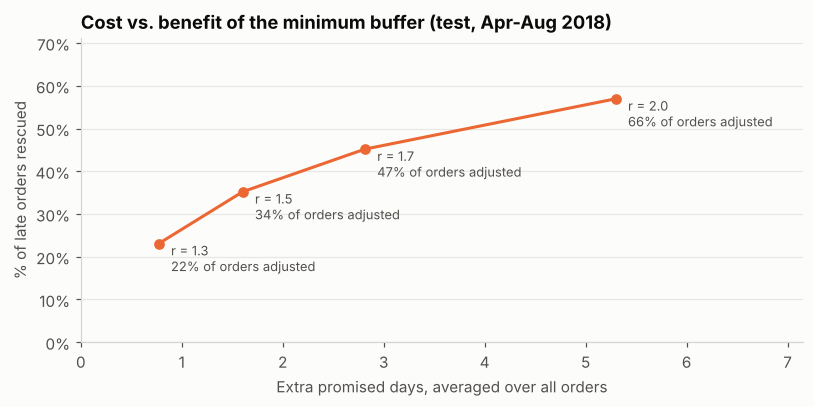

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(policy["mean extra days (all)"], 100 * policy["% of late orders rescued"], color=ORANGE, marker="o", markersize=6)
for r, row in policy.iterrows():
    ax.annotate(f"r = {r}\n{row['% orders with adjusted promise']:.0%} of orders adjusted",
                (row["mean extra days (all)"], 100 * row["% of late orders rescued"]),
                textcoords="offset points", xytext=(8, -18), fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Extra promised days, averaged over all orders")
ax.set_ylabel("% of late orders rescued")
ax.set_title("Cost vs. benefit of the minimum buffer (test, Apr-Aug 2018)")
ax.set_xlim(0, policy["mean extra days (all)"].max() * 1.35)
ax.set_ylim(0, 100 * policy["% of late orders rescued"].max() * 1.25)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/07_policy_tradeoff.png", dpi=160)

The table shows the trade-off the business has to decide on: each extra point of avoided delays costs additional promised days for a share of customers.

- Conservative option, r = 1.3: adjusts the promise for 22% of orders, by +3.6 days on average for those orders (+0.8 across all orders). It rescues 23% of late orders (398 in five months) and avoids ~85 negative reviews.
- Middle option, r = 1.5: rescues 35% in exchange for +4.7 days for a third of the orders.

An important limitation: a longer promise can reduce conversion (a customer who sees "arrives in 20 days" might not buy). This dataset cannot measure that effect, because it only contains completed purchases. That is why the recommendation is to roll it out as an A/B test: one group with the minimum buffer and one without, measuring conversion and reviews.

## 10. Export results

- Test-period predictions for the dashboard's "Risk" page.
- Experiment metrics as JSON, for reproducibility.

In [14]:
predictions = test[["order_id", "purchase_ts", "main_seller_id", "customer_state", "seller_state", "route",
                    "promised_days", "route_hist_days", "promise_ratio", "is_late", "delivery_status"]].copy()
predictions["purchase_date"] = predictions.pop("purchase_ts").dt.date
predictions["late_probability"] = test_scores["Logistic regression"].round(4)
predictions["risk_percentile"] = (pd.Series(-test["promise_ratio"].to_numpy()).rank(pct=True).to_numpy() * 100).round(1)
predictions["flag_high_risk"] = flag.astype(int)
predictions = predictions.rename(columns={"main_seller_id": "seller_id"})
predictions.to_csv("../data/processed/test_predictions.csv", index=False)

run_meta = {
    "config": asdict(cfg),
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "test_late_rate": float(y_test.mean()),
    "validation": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in val_table.T.to_dict().items()},
    "test": {name: {m: round(float(v), 4) for m, v in metrics(y_test, s, cfg.capacity).items()} for name, s in test_scores.items()},
    "backtest_mean_capture_top10": {k: round(float(v), 4) for k, v in capture_by_month.mean().items()},
    "rule_threshold_fixed_promise_ratio": round(fixed_threshold, 4),
    "rule_threshold_rolling_test": {"flagged_share": round(float(flag.mean()), 4),
                            "capture": round(float(y_test[flag].sum() / y_test.sum()), 4),
                            "precision": round(float(y_test[flag].mean()), 4)},
    "promise_policy": {str(r): {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
                                for k, v in row.items()} for r, row in policy.iterrows()},
}
with open("../reports/model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(run_meta, f, ensure_ascii=False, indent=2)
print(f"{len(predictions):,} predictions → data/processed/test_predictions.csv")
print("Metrics → reports/model_metrics.json")

32,453 predictions → data/processed/test_predictions.csv
Metrics → reports/model_metrics.json


## Experiment summary

| | |
|---|---|
| Data | 97,300 orders (2017-01 to 2018-08) with a known delivery outcome |
| Split | Time-based: validation Jan-Mar 2018, test Apr-Aug 2018; monthly backtest Oct 2017-Aug 2018 |
| Baseline | Promise buffer rule |
| Result | The rule catches 29.4% of late orders by reviewing 10% of orders (CI 27.4–31.3%), ~3 times random |
| Models | Logistic regression and gradient boosting come in ~3.5 points below the rule on test (significant difference) |
| Leakage audit | Histories verified by brute force; priors and encoders fitted on the past only |
| Decision | Operate with the rule (interpretable, no retraining) and test the minimum buffer with an A/B test |